In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


c:\Users\luca0\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("nafiulislam490/bank-transaction-fraud-detection-dataset")
df = pd.read_csv(f"{path}/bank_fraud.csv").sample(n=20000, random_state=33)


df = df.drop(columns=['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'fraud_type'])

In [3]:
le = LabelEncoder()
df_encoded = df.apply(le.fit_transform)
df_encoded

,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,...,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud
528067,20,0,0,9,17,7,2,2,46,246,...,2870,722,81,12,98,1582,0,0,0,0
707386,23,0,1,0,13,10,0,0,4,374,...,8221,12915,26,21,276,56,1,0,0,0
460725,20,0,0,9,14,5,3,2,21,176,...,14175,3863,33,14,464,108,0,0,0,0
536079,23,0,1,6,18,0,2,3,22,230,...,8842,7446,33,8,228,1055,0,0,1,0
156756,5,0,1,9,5,11,5,3,8,297,...,13955,7478,59,15,259,1625,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644409,14,0,0,6,5,1,5,2,24,305,...,11892,2035,54,12,87,3316,0,0,0,0
996559,21,0,0,8,3,11,5,2,9,218,...,9114,1581,48,10,1,2792,0,0,0,0
863794,1,0,1,9,10,13,2,1,40,369,...,12341,11617,20,13,41,93,0,0,0,0
701232,8,0,0,2,1,11,2,0,28,268,...,10262,5881,60,27,127,758,0,0,1,0


In [4]:
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1:]

In [5]:
sm = SMOTE(random_state=33)
X, y = sm.fit_resample(X, y)
y_num = np.asarray(y).ravel()

<Axes: >

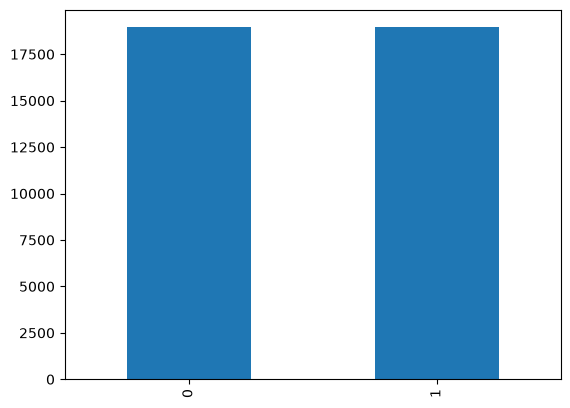

In [6]:
y_num = np.asarray(y).ravel()
pd.Series.value_counts(y_num).plot.bar()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, shuffle=True)

In [8]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, AdaBoostClassifier

column_names = list(df.columns.values)
feature_names = [f"{column_names[i]}" for i in range(X.shape[1])]
forest = RandomForestClassifier(n_estimators=100, random_state=33)
forest.fit(X_train, y_train)

c:\Users\luca0\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",33
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [9]:
y_prediction = forest.predict(X_test)

print('Acuracidade do Algoritmo: ', accuracy_score(y_test, y_prediction))
print('Precisão do Algoritmo:    ', precision_score(y_test, y_prediction, average='weighted'))
print('Recall do Algoritmo:      ', recall_score(y_test, y_prediction, average='weighted'))
print('F1 do Algoritmo:          ', f1_score(y_test, y_prediction, average='weighted'))

Acuracidade do Algoritmo:  0.9256881540761587
Precisão do Algoritmo:     0.9259740888780065
Recall do Algoritmo:       0.9256881540761587
F1 do Algoritmo:           0.9256763244249823


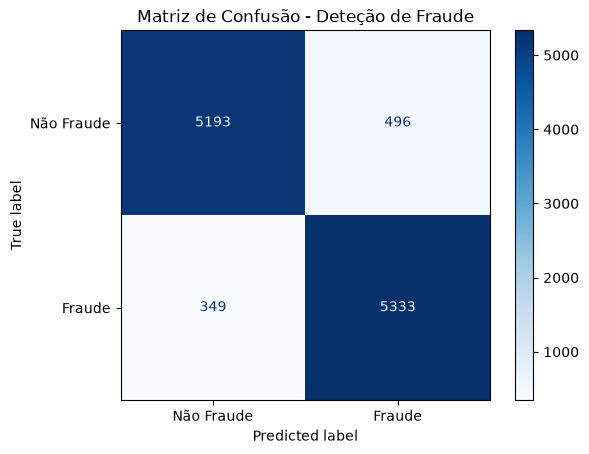

In [10]:
disp = ConfusionMatrixDisplay.from_estimator(
    forest, 
    X_test, 
    y_test,
    display_labels=['Não Fraude', 'Fraude'],
    cmap=plt.cm.Blues,
    values_format='d'
)

plt.title('Matriz de Confusão - Deteção de Fraude')
plt.grid(False)
plt.show()

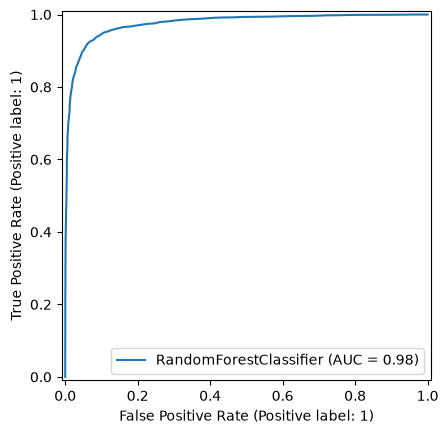

In [11]:
# Gerando a curva ROC do modelo
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split
RocCurveDisplay.from_estimator(forest, X_test, y_test)
plt.show()